# Cahn-Hilliard equation

This tutorial follows the Cahn-Hilliard demo of
[DOLFINx](https://docs.fenicsproject.org/dolfinx/main/python/demos.html), written in
the Firedrake style.
The concentration $c$ of a binary mixture evolves by

$$ \partial_t c - \nabla\cdot\big(M \nabla\mu\big) = 0, \qquad
   \mu = \frac{\mathrm d f}{\mathrm d c} - \lambda\Delta c ,$$

with the double well $f(c) = 100\,c^2(1-c)^2$, mobility $M=1$, and homogeneous natural
boundary conditions $M\nabla\mu\cdot n = \lambda\nabla c\cdot n = 0$.  The fourth order equation is split into the
two second order equations for $(c,\mu)$, which are discretised with piecewise linears
and tested with $(q, v)$:

$$ \int c\,q\,dx + \Delta t \int \nabla\mu_{\theta}\cdot\nabla q\,dx = \int c_n q\,dx, \qquad
   \int \mu\, v\,dx = \int f'(c)\, v\,dx + \lambda\int \nabla c\cdot\nabla v\,dx, $$

where $\mu_\theta = (1-\theta)\mu_n + \theta\mu$.  The scheme with $\theta = 1/2$ is
Crank-Nicolson; the system is nonlinear in $c$ and solved by Newton's method in every step.
Two properties of the continuous problem should carry over: the total mass
$\int c\,dx$ is conserved, and the free energy
$E(c) = \int f(c) + \tfrac{\lambda}{2}|\nabla c|^2\,dx$ decays.

## Chemical potential with `variable` and `diff`

The derivative $f'(c)$ is not typed by hand: wrapping $c$ in `variable` and calling `diff`
lets UFL differentiate the energy density symbolically.  The Newton Jacobian is not
supplied either, since NGSolve differentiates the residual itself (Firedrake would use
UFL; `J=derivative(F, u)` does the same here).

In [1]:
from ngsufl import *
import numpy as np

mesh = UnitSquareMesh(40, 40)
P1 = FunctionSpace(mesh, "CG", 1)
ME = P1 * P1

q, v = TestFunctions(ME)
u = Function(ME, name="u")
u0 = Function(ME, name="u0")
c, mu = split(u)
c0, mu0 = split(u0)

lmbda = 1.0e-2
dt = 5.0e-6
theta = 0.5

c = variable(c)
f = 100 * c**2 * (1 - c) ** 2
dfdc = diff(f, c)

mu_mid = (1 - theta) * mu0 + theta * mu
F0 = c * q * dx - c0 * q * dx + dt * dot(grad(mu_mid), grad(q)) * dx
F1 = mu * v * dx - dfdc * v * dx - lmbda * dot(grad(c), grad(v)) * dx
F = F0 + F1

## Initial condition

The initial concentration is a random perturbation of 0.63.  For degree 1 the dofs of a
`Function` are the vertex values, so we can fill the data array of the first
sub-function directly.

In [2]:
rng = np.random.default_rng(42)
u.subfunctions[0].dat.data[:] = 0.63 + 0.02 * (0.5 - rng.random(P1.dim()))
u0.assign(u)

problem = NonlinearVariationalProblem(F, u)
solver = NonlinearVariationalSolver(problem, solver_parameters={"snes_rtol": 1e-8, "snes_atol": 1e-10})

## Time stepping

In each step we copy the current state into `u0` and solve for the new one.  A first
solve of the mixed system also provides a consistent initial $\mu$ (it starts from zero).
Mass and energy are monitored, and four snapshots of $c$ are stored.

In [3]:
c_now = u.subfunctions[0]
energy_form = (100 * c_now**2 * (1 - c_now) ** 2 + 0.5 * lmbda * dot(grad(c_now), grad(c_now))) * dx

nsteps = 100
snap_at = {0, 25, 50, 100}
snaps, mass, energy, newton = {}, [assemble(c_now * dx)], [assemble(energy_form)], []
snaps[0] = (0.0, c_now.copy())

for step in range(1, nsteps + 1):
    u0.assign(u)
    solver.solve()
    newton.append(solver.iterations)  # ngsufl extra; Firedrake: solver.snes.getIterationNumber()
    mass.append(assemble(c_now * dx))
    energy.append(assemble(energy_form))
    if step in snap_at:
        snaps[step] = (step * dt, c_now.copy())

print("Newton iterations per step: min", min(newton), "max", max(newton))
print("mass   at t=0:", mass[0], " at t=T:", mass[-1])
print("max |mass drift|:", max(abs(m - mass[0]) for m in mass))
print("energy at t=0:", energy[0], " at t=T:", energy[-1])
print("energy non-increasing:", all(e1 <= e0 * (1 + 1e-10) for e0, e1 in zip(energy, energy[1:])))

Newton iterations per step: min 2 max 5
mass   at t=0: 0.6300059092839515  at t=T: 0.6300059092839526
max |mass drift|: 2.9976021664879227e-15
energy at t=0: 5.433876561095277  at t=T: 2.335367771870922
energy non-increasing: True


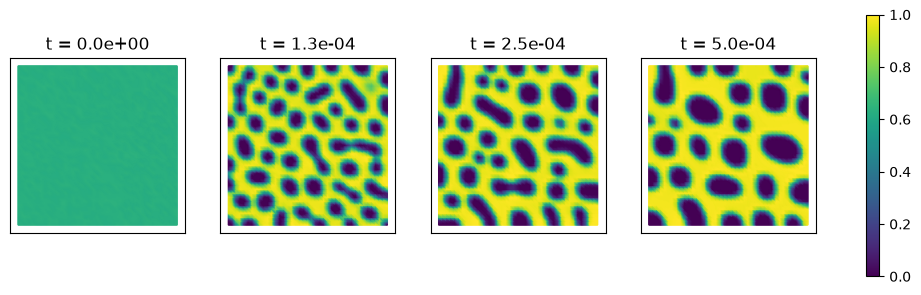

In [4]:
import matplotlib.pyplot as plt
from ngsufl.pyplot import tripcolor

fig, axs = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (step, (t, cs)) in zip(axs, sorted(snaps.items())):
    colors = tripcolor(cs, axes=ax, vmin=0.0, vmax=1.0)
    ax.set_title(f"t = {t:.1e}")
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(colors, ax=axs);

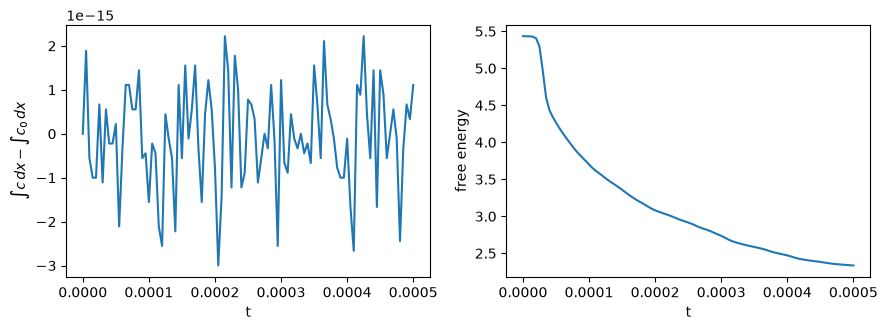

In [5]:
t = dt * np.arange(nsteps + 1)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
axs[0].plot(t, np.array(mass) - mass[0])
axs[0].set_xlabel("t"); axs[0].set_ylabel(r"$\int c\,dx - \int c_0\,dx$")
axs[1].plot(t, energy)
axs[1].set_xlabel("t"); axs[1].set_ylabel("free energy")
fig.tight_layout();

Mass is conserved to solver round-off, because testing the first equation with $q=1$
kills the diffusion term exactly, whatever the Newton tolerance.  The energy decreases
monotonically as the mixture separates into the two phases, towards the two
minima $c=0$ and $c=1$ of the double well.